# 5. Pattern Detection

In this notebook, we look for meaningful patterns in the car sales data — such as how prices change with age, which car models hold their value best, and how usage and seller type affect pricing. Each section focuses on one specific pattern or trend.

## 5.1 Setup and Load Data

**Task:** Import all the libraries we need and load the cleaned car sales dataset so we are ready to analyse it.

We import standard data science libraries (pandas, numpy, matplotlib, seaborn) and add the project's `src` folder to Python's path so we can use the shared config and figure-saving helper.

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, '..')
from src.config import SECTION_FIGURE_DIRS
from src.plot_utils import save_figure

import warnings
warnings.filterwarnings('ignore')

We read the dataset from the CSV file and print the shape so we can confirm all rows and columns loaded correctly.

In [4]:
DATASET_PATH = Path('../data/final_destination.csv')
df = pd.read_csv(DATASET_PATH)

print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())

Dataset shape: 15,229 rows × 15 columns


,model,vehicle_age,km_driven,seller_type,transmission_type,mileage,engine,max_power,selling_price,real_typical_owner_type,real_avg_owner_count,real_common_trim,real_new_ex_showroom_price,real_body_type,model_grouped
0,Alto,9,120000,Individual,Manual,19.70,796,46.30,120000,First,1.15,LXi,0.519500,Unknown,Alto
1,Grand,5,20000,Individual,Manual,18.90,1197,82.00,550000,First,1.08,i10 Sportz,0.641574,Hatchback,Grand
2,i20,11,60000,Individual,Manual,17.00,1197,80.00,215000,First,1.18,1.2 Magna,0.820343,Hatchback,i20
3,Alto,9,37000,Individual,Manual,20.92,998,67.10,226000,First,1.15,LXi,0.519500,Unknown,Alto
4,Ecosport,6,30000,Dealer,Manual,22.77,1498,98.59,570000,First,1.08,1.5 DV5 MT Titanium Optional,0.856000,SUV,Ecosport


## 5.2 Price Trend by Vehicle Age

**Task:** Find out how the selling price changes as a car gets older — specifically, does the price drop steadily every year or are there certain ages where the drop is sharper?

We group all cars by their age in years and compute the median selling price for each age, along with the 25th and 75th percentile prices to show the typical spread.

In [5]:
age_stats = (
    df.groupby('vehicle_age')['selling_price']
    .agg(median='median', q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75))
    .reset_index()
)
age_stats = age_stats[age_stats['vehicle_age'] <= 20]  # focus on 0-20 years
display(age_stats.head(10))

,vehicle_age,median,q25,q75
0,0,525000.0,475000.0,1625000.0
1,1,750000.0,550000.0,1056250.0
2,2,818000.0,586250.0,1098000.0
3,3,748000.0,550000.0,950000.0
4,4,695500.0,518000.0,911250.0
5,5,600000.0,450000.0,789000.0
6,6,550000.0,450000.0,700000.0
7,7,500000.0,395000.0,650000.0
8,8,450000.0,350000.0,600000.0
9,9,400000.0,300000.0,600000.0


We draw a line chart of median price over age and shade the area between the 25th and 75th percentiles to show where most prices fall at each age.

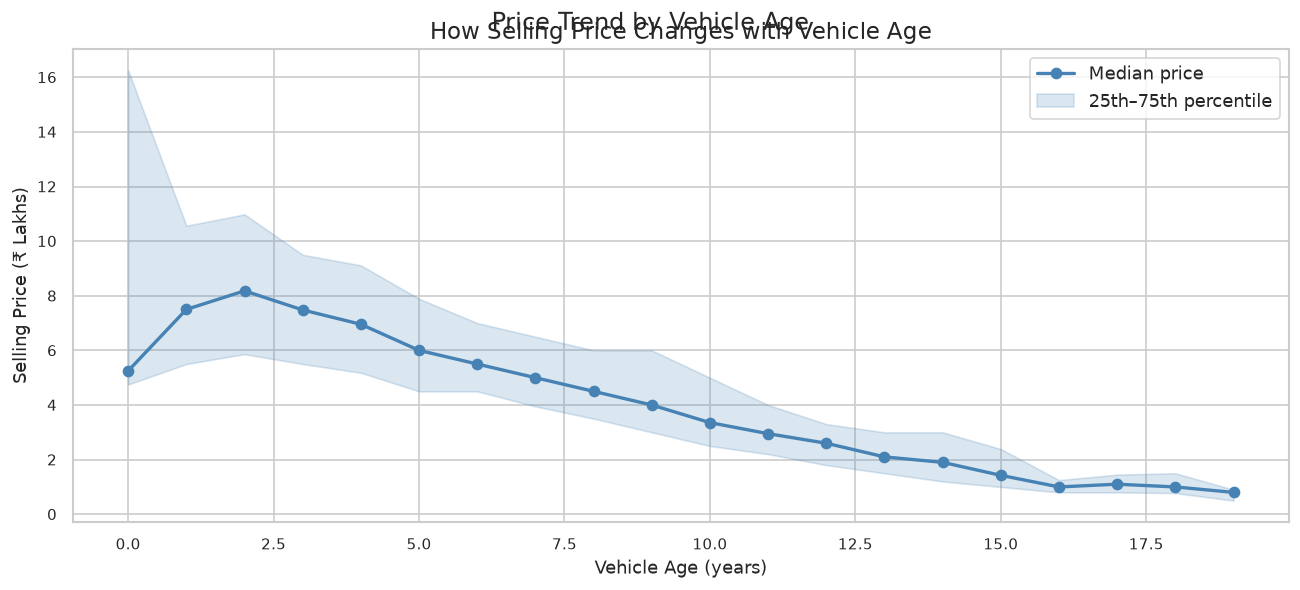

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(age_stats['vehicle_age'], age_stats['median'] / 1e5,
        marker='o', linewidth=2, color='steelblue', label='Median price')
ax.fill_between(age_stats['vehicle_age'],
                age_stats['q25'] / 1e5,
                age_stats['q75'] / 1e5,
                alpha=0.2, color='steelblue', label='25th–75th percentile')

ax.set_xlabel('Vehicle Age (years)')
ax.set_ylabel('Selling Price (₹ Lakhs)')
ax.set_title('How Selling Price Changes with Vehicle Age')
ax.legend()
plt.tight_layout()

save_figure(fig, 'price_vs_age.png', section=5, title='Price Trend by Vehicle Age')
plt.show()

**Key observations:**

- Prices drop the fastest in the first 3–5 years, which is when depreciation is steepest.
- After about 8 years, the rate of decline slows down and prices level off.
- The price band (shaded area) is widest for newer cars, meaning there is more variability in what people pay for recent models.

## 5.3 Mileage vs Selling Price by Body Type

**Task:** Check whether the relationship between a car's fuel efficiency (mileage) and its selling price looks the same across different body types, or if certain types behave differently.

We remove rows with an 'Unknown' body type and pick the five most common body types so the charts are not too cluttered.

In [7]:
df_known = df[df['real_body_type'] != 'Unknown'].copy()
top5_body = df_known['real_body_type'].value_counts().nlargest(5).index.tolist()
df_top5 = df_known[df_known['real_body_type'].isin(top5_body)].copy()
print('Body types included:', top5_body)
print('Rows after filter:', len(df_top5))

Body types included: ['Hatchback', 'Sedan', 'SUV', 'MUV', 'Crossover, SUV']
Rows after filter: 9871


We create a separate scatter plot for each body type with a regression line so we can see whether mileage and price move together or not within each group.

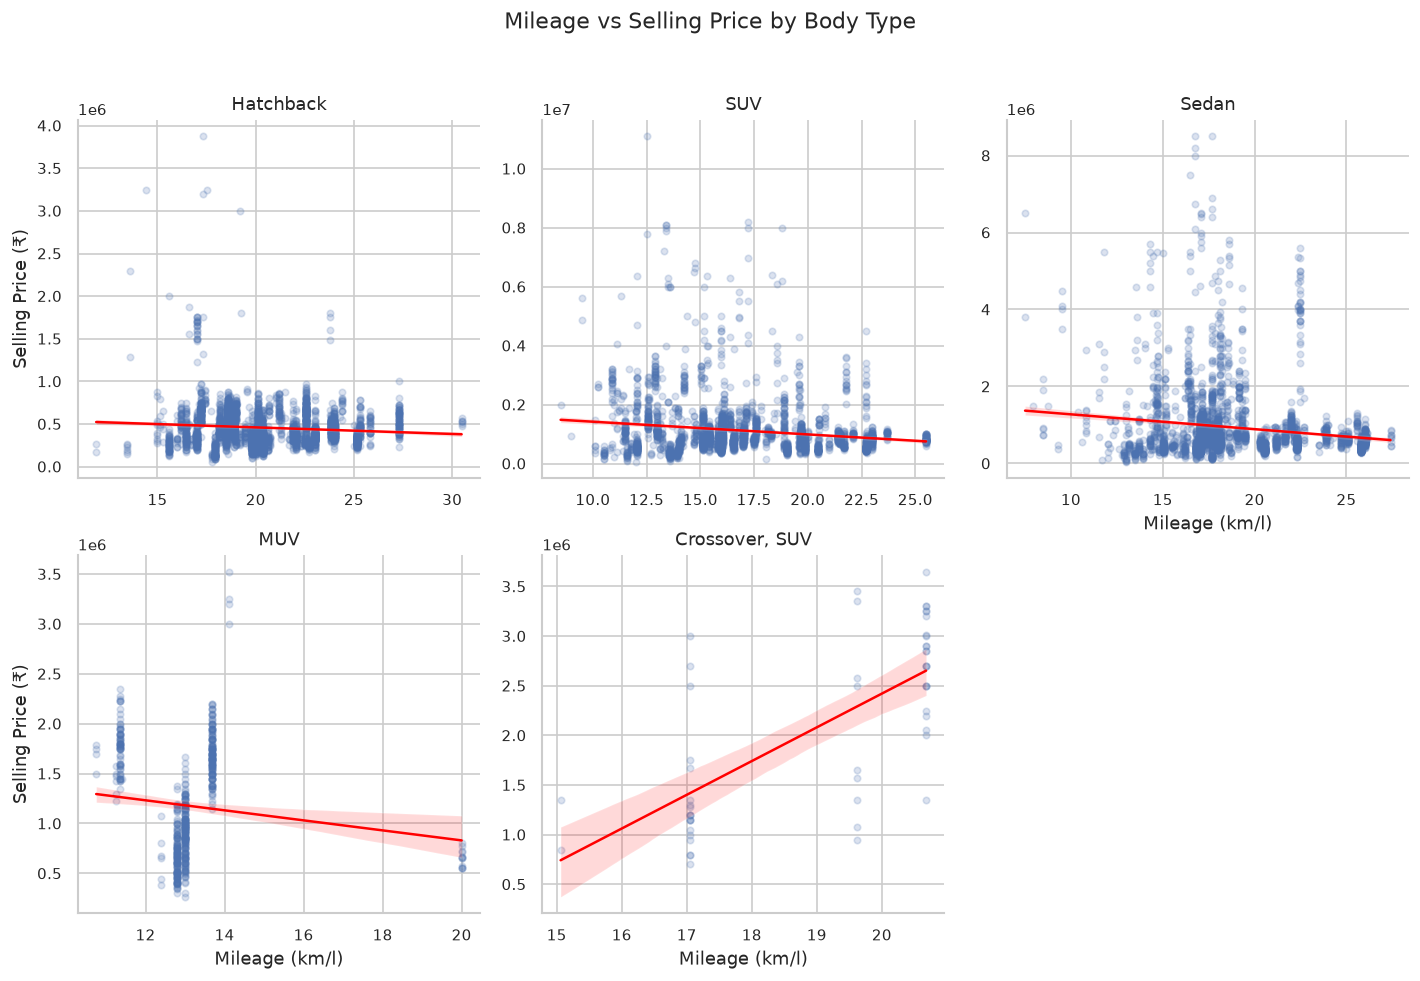

In [8]:
g = sns.FacetGrid(df_top5, col='real_body_type', col_wrap=3,
                  height=4, sharey=False, sharex=False)
g.map_dataframe(sns.regplot, x='mileage', y='selling_price',
                scatter_kws={'alpha': 0.2, 's': 15},
                line_kws={'color': 'red', 'linewidth': 1.5})
g.set_axis_labels('Mileage (km/l)', 'Selling Price (₹)')
g.set_titles(col_template='{col_name}')
g.figure.suptitle('Mileage vs Selling Price by Body Type', y=1.02, fontsize=13)
plt.tight_layout()

save_figure(g.figure, 'mileage_vs_price_by_body.png', section=5)
plt.show()

**Key observations:**

- Hatchbacks and Sedans show a weak negative trend — higher mileage cars tend to sell for slightly less, possibly because they are older budget models.
- SUVs show a flatter or slightly positive pattern, suggesting buyers care less about mileage and more about features when buying an SUV.
- The scatter is wide in all panels, meaning mileage alone is not a strong predictor of price within any body type.

## 5.4 Kilometre-Driven Usage Clusters

**Task:** Group cars into usage categories based on how many kilometres they have been driven, then compare the selling prices across those groups to see if lower-usage cars command a higher price.

We cut `km_driven` into four labelled bins — Low, Medium, High, and Very High — which turns a continuous number into a meaningful category we can group and compare.

In [9]:
bins   = [0, 30_000, 70_000, 150_000, df['km_driven'].max() + 1]
labels = ['Low\n(<30k km)', 'Medium\n(30k–70k)', 'High\n(70k–150k)', 'Very High\n(>150k)']

df['km_bin'] = pd.cut(df['km_driven'], bins=bins, labels=labels, right=False)
print(df['km_bin'].value_counts().sort_index())

km_bin
Low\n(<30k km)        3685
Medium\n(30k–70k)     7299
High\n(70k–150k)      3942
Very High\n(>150k)     303
Name: count, dtype: int64


We first plot a simple count bar chart to see how many cars fall into each usage group.

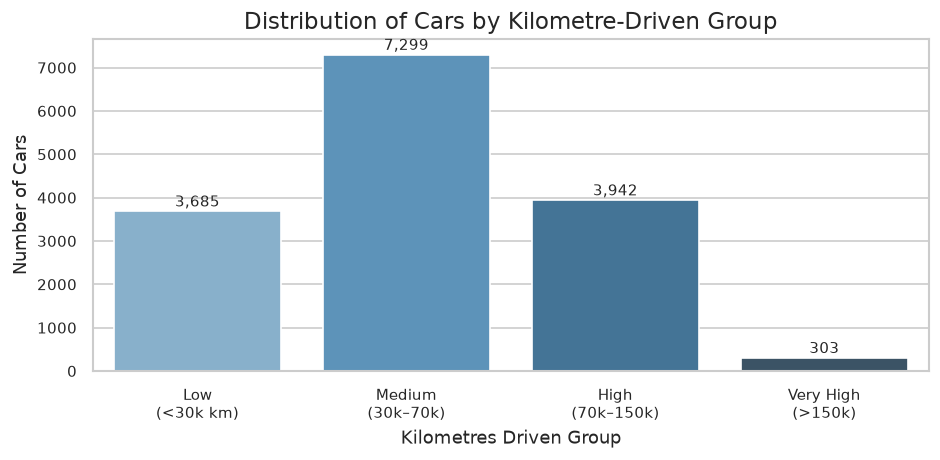

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
counts = df['km_bin'].value_counts().sort_index()
sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_d')
ax.set_xlabel('Kilometres Driven Group')
ax.set_ylabel('Number of Cars')
ax.set_title('Distribution of Cars by Kilometre-Driven Group')
for bar, val in zip(ax.patches, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
            f'{val:,}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
save_figure(fig, 'km_group_counts.png', section=5)
plt.show()

Next, we draw a box plot to compare the spread and median selling price within each kilometre-driven group.

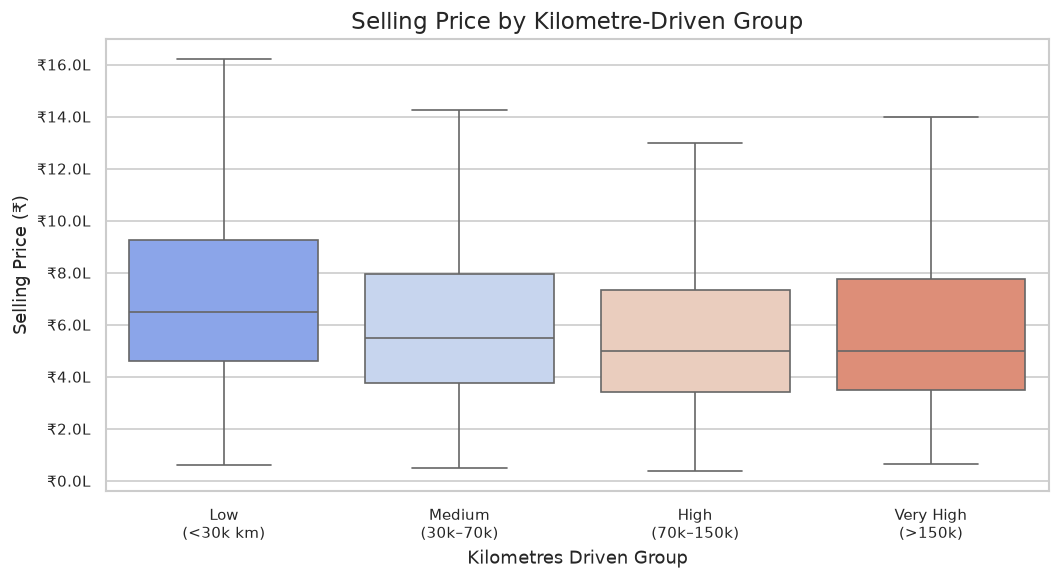

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x='km_bin', y='selling_price',
            order=labels, palette='coolwarm', ax=ax,
            showfliers=False)  # hide extreme outliers for clarity
ax.set_xlabel('Kilometres Driven Group')
ax.set_ylabel('Selling Price (₹)')
ax.set_title('Selling Price by Kilometre-Driven Group')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'₹{x/1e5:.1f}L'))
plt.tight_layout()
save_figure(fig, 'km_group_price_box.png', section=5)
plt.show()

**Key observations:**

- Cars with lower kilometre readings (Low group) have the highest median selling prices, as expected.
- The price drops noticeably from the Medium to High group, confirming that heavy usage hurts resale value.
- The Very High group has the lowest and tightest price range, suggesting these cars are mostly budget-level purchases.

## 5.5 Transmission Type — Price Pattern Over Age

**Task:** Compare how Manual and Automatic cars depreciate over time to see if one type holds its value better as it gets older.

We group by both vehicle age and transmission type, then compute the median selling price for each combination so we can draw two separate lines on the same chart.

In [12]:
trans_age = (
    df[df['vehicle_age'] <= 20]
    .groupby(['vehicle_age', 'transmission_type'])['selling_price']
    .median()
    .reset_index()
)
display(trans_age.head(10))

,vehicle_age,transmission_type,selling_price
0,0,Automatic,4850000.0
1,0,Manual,500000.0
2,1,Automatic,1185000.0
3,1,Manual,690000.0
4,2,Automatic,1100000.0
5,2,Manual,750000.0
6,3,Automatic,925000.0
7,3,Manual,700000.0
8,4,Automatic,1095000.0
9,4,Manual,650000.0


We plot both transmission types on the same line chart so it is easy to see whether the gap between them widens, narrows, or stays constant as cars age.

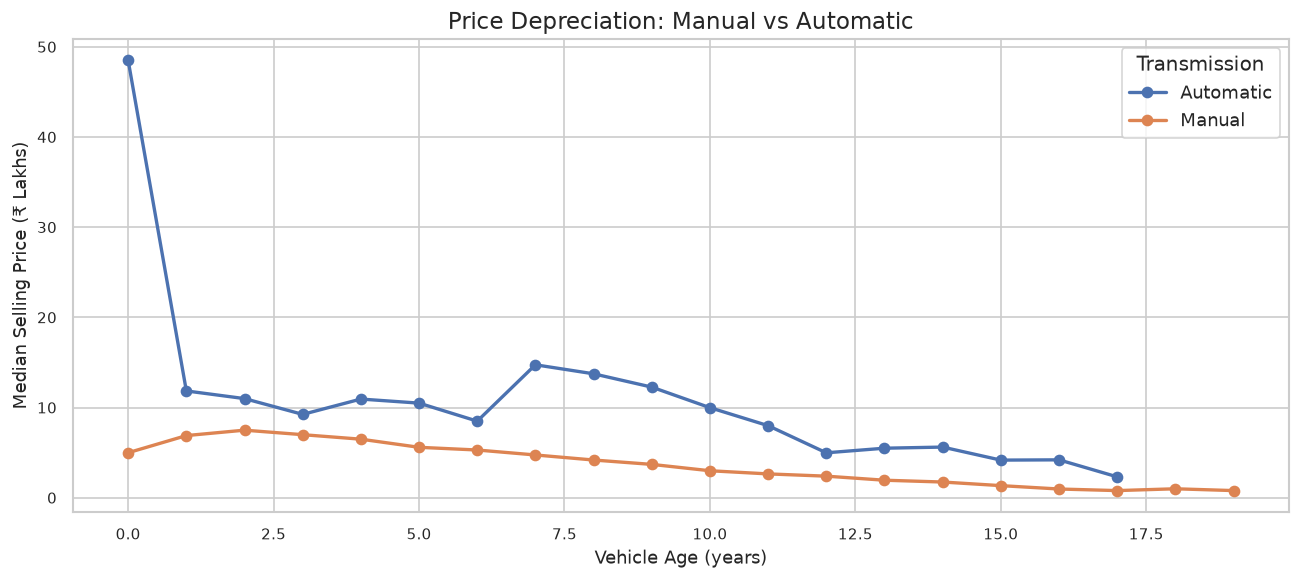

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
for trans, grp in trans_age.groupby('transmission_type'):
    ax.plot(grp['vehicle_age'], grp['selling_price'] / 1e5,
            marker='o', linewidth=2, label=trans)

ax.set_xlabel('Vehicle Age (years)')
ax.set_ylabel('Median Selling Price (₹ Lakhs)')
ax.set_title('Price Depreciation: Manual vs Automatic')
ax.legend(title='Transmission')
plt.tight_layout()
save_figure(fig, 'price_by_transmission_age.png', section=5)
plt.show()

**Key observations:**

- Automatic cars start at a much higher median price when new, reflecting their higher purchase cost.
- Both types depreciate at a similar pace, but Automatics maintain a premium over Manuals at almost every age.
- By age 10+, the price gap between the two narrows significantly, suggesting older Automatics lose their premium faster.

## 5.6 Top Models by Median Resale Value

**Task:** Identify which car models command the highest median resale prices so buyers and sellers know which brands hold their value best in the used market.

We compute the median selling price for each model group and select the top 15, making sure each model has at least 30 listings so the result is statistically meaningful.

In [14]:
model_stats = (
    df.groupby('model_grouped')
    .agg(median_price=('selling_price', 'median'), count=('selling_price', 'count'))
    .query('count >= 30')
    .sort_values('median_price', ascending=False)
    .head(15)
    .reset_index()
)
display(model_stats)

,model_grouped,median_price,count
0,GL-Class,3662500.0,36
1,Rare_Sedan,3650000.0,39
2,Rover,3487500.0,50
3,7,2970000.0,36
4,5,2600000.0,117
5,S-Class,2450000.0,36
6,Rare_SUV,2425000.0,54
7,XF,2400000.0,51
8,Endeavour,2367500.0,42
9,X1,2125000.0,54


We draw a horizontal bar chart sorted from highest to lowest median price, which makes it easy to rank and compare models at a glance.

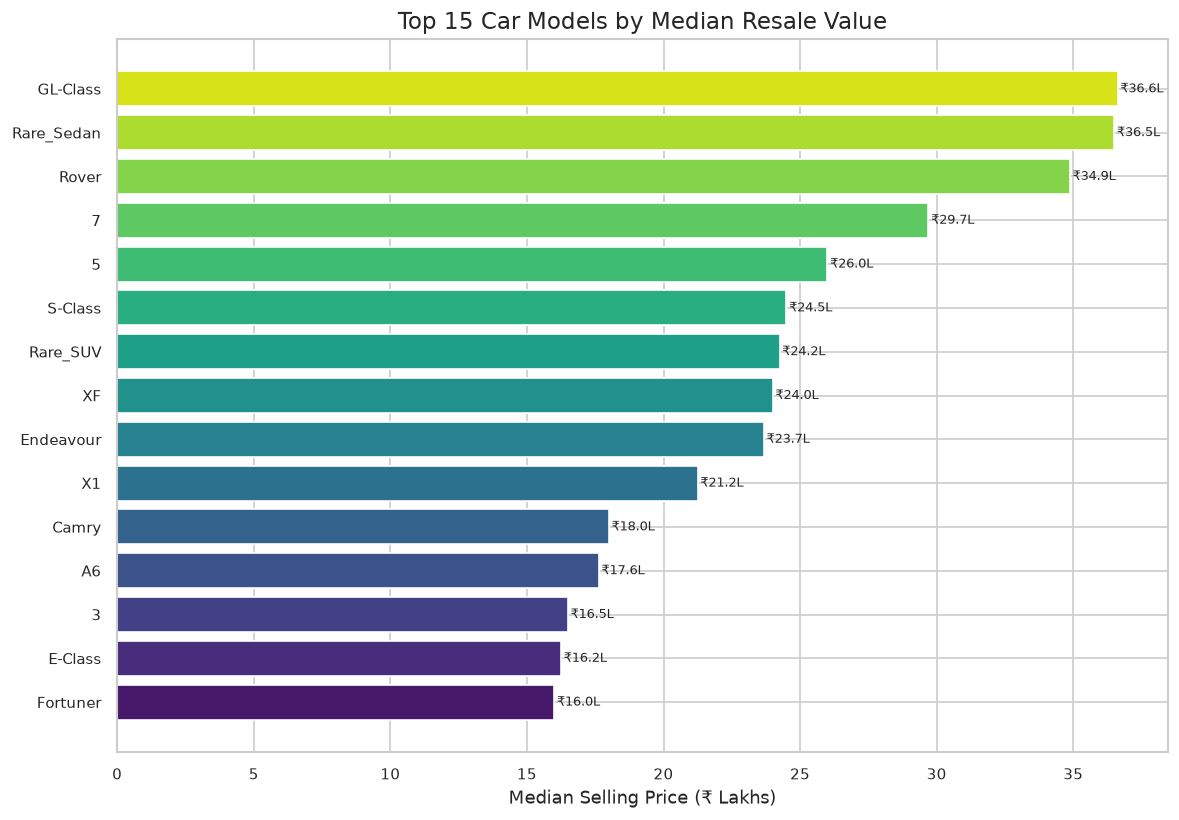

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(model_stats['model_grouped'][::-1],
               model_stats['median_price'][::-1] / 1e5,
               color=sns.color_palette('viridis', len(model_stats)))
ax.set_xlabel('Median Selling Price (₹ Lakhs)')
ax.set_title('Top 15 Car Models by Median Resale Value')
for bar, val in zip(bars, model_stats['median_price'][::-1] / 1e5):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
            f'₹{val:.1f}L', va='center', fontsize=8)
plt.tight_layout()
save_figure(fig, 'top_models_resale.png', section=5)
plt.show()

**Key observations:**

- Premium and SUV models (like Fortuner, Innova, and high-end sedans) dominate the top resale values.
- Entry-level hatchbacks like Alto and i10 appear at the lower end, consistent with their lower new-car prices.
- Models with strong brand loyalty and wide service networks tend to retain value better.

## 5.7 Seller Type and Price Spread

**Task:** Compare how the asking price varies depending on who is selling — an individual, a dealer, or a trustmark dealer — to see if the seller type is associated with higher or more consistent prices.

We create a violin plot, which shows both the median price and the full distribution shape for each seller type, making it easy to see which sellers list cars at more extreme prices.

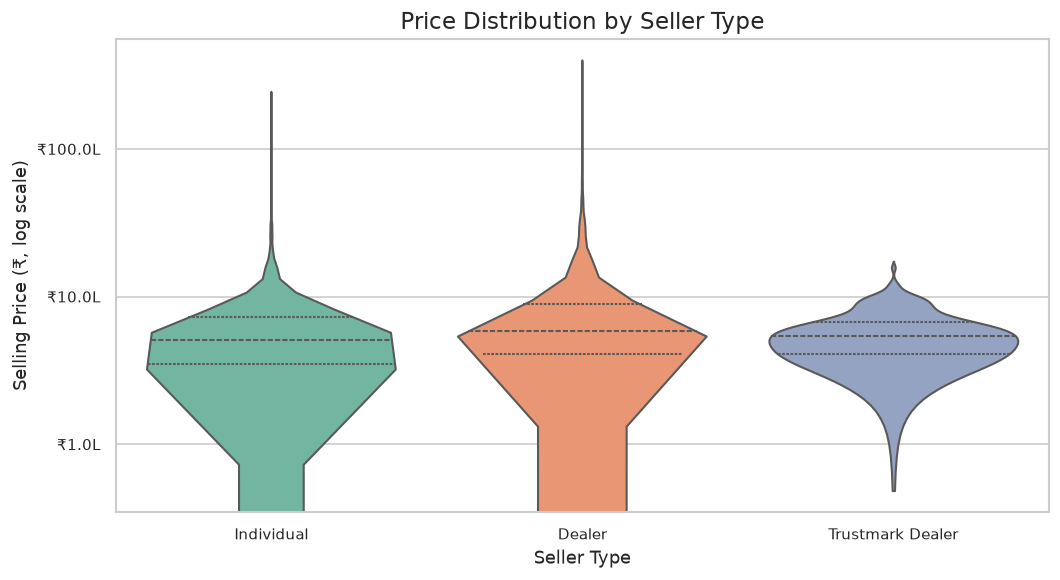

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.violinplot(data=df, x='seller_type', y='selling_price',
               order=['Individual', 'Dealer', 'Trustmark Dealer'],
               palette='Set2', inner='quartile', ax=ax)

ax.set_yscale('log')
ax.set_xlabel('Seller Type')
ax.set_ylabel('Selling Price (₹, log scale)')
ax.set_title('Price Distribution by Seller Type')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'₹{x/1e5:.1f}L' if x >= 1e5 else f'₹{int(x):,}'))
plt.tight_layout()
save_figure(fig, 'price_by_seller_type.png', section=5)
plt.show()

**Key observations:**

- Dealers tend to list cars at higher prices and have a wider price range, likely because they carry a broader inventory.
- Individual sellers cluster around lower prices, which may reflect a mix of older or high-mileage cars.
- Trustmark Dealers have the narrowest distribution, suggesting they specialise in a particular quality or price segment.